# N777 (Boeing 777, N577NA) Platform Parameterization

**Name:** N777_platform_parameterization  

**Purpose:**  
Derive platform parameterization values for the Boeing 777 (tail N577NA) from actual
NURTURE IWG1 flight data: ground speed vs altitude, vertical speed, bank angle in turns,
cruise altitude, and speed–altitude slope.  Used to fill in the `n577na` entry in the
platform configuration file.

The IWG1 files have significant missing data: GPS MSL altitude, true airspeed, vertical
velocity, and roll angle are all absent.  Available fields are:
- **Radar Altitude** (ft) — used here as proxy for flight altitude (likely pressure altitude)
- **Ground Speed** (m/s)
- **True Heading** (deg)
- **Latitude / Longitude**

Missing quantities are derived:
- **Vertical speed** from `d(alt)/dt`
- **Bank angle** from the coordinated-turn formula: `φ = arctan(ω·v/g)`

**Input:**  
- `/data2/NURTURE/N777/IWG1_N577NA_20260716.txt`  
- `/data2/NURTURE/N777/IWG1_N577NA_20260801.txt`

**Output:** plots, printed platform parameter values  

**Dependencies:** numpy, scipy, pandas, matplotlib  

**History:**  
Written: Samuel LeBlanc, Santa Cruz, CA, 2026-08-17

# Prepare the Python Environment

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as st
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import os

In [2]:
%matplotlib inline

# Load IWG1 Data

The IWG1 CSV files have one header row.  Only Radar Altitude, Ground Speed, True Heading,
Latitude, and Longitude carry real data; everything else is NaN.  Radar Altitude is in feet
and spans the full flight-altitude range (1 600 – 43 000 ft), consistent with pressure
altitude rather than a true radar-altimeter reading.

In [3]:
DATA_DIR = '/data2/NURTURE/N777/'
FILES = {
    'Jul16': 'IWG1_N577NA_20260716.txt',
    'Aug01': 'IWG1_N577NA_20260801.txt',
}

RENAME = {
    'Radar Altitude': 'alt_ft',
    'Ground Speed':   'gspd_ms',
    'True Heading':   'heading',
    'Latitude':       'lat',
    'Longitude':      'lon',
}

def load_iwg1(fp, flight_label):
    df = pd.read_csv(fp)
    df.columns = df.columns.str.strip()
    df['time'] = pd.to_datetime(df['TimeStamp'], utc=True)
    df = df.sort_values('time').reset_index(drop=True)
    df['flight'] = flight_label
    df = df.rename(columns=RENAME)
    for col in ['alt_ft', 'gspd_ms', 'heading', 'lat', 'lon']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df['alt_m']    = df['alt_ft'] * 0.3048
    df['gspd_kts'] = df['gspd_ms'] * 1.94384
    return df

dfs = {}
for label, fname in FILES.items():
    fp = os.path.join(DATA_DIR, fname)
    dfs[label] = load_iwg1(fp, label)

for label, df in dfs.items():
    print(f'Flight {label}: {len(df)} records, '
          f"{df['time'].iloc[0].strftime('%H:%M')}–"
          f"{df['time'].iloc[-1].strftime('%H:%M')} UTC")
    print(f"  Alt (ft):  {df['alt_ft'].min():.0f} – {df['alt_ft'].max():.0f}")
    print(f"  Alt (m):   {df['alt_m'].min():.0f} – {df['alt_m'].max():.0f}")
    print(f"  GS (m/s):  {df['gspd_ms'].min():.1f} – {df['gspd_ms'].max():.1f}")
    print(f"  GS (kts):  {df['gspd_kts'].min():.0f} – {df['gspd_kts'].max():.0f}")
    ok = [c for c in df.columns if df[c].notna().any()
          and c not in ['HEADER','TimeStamp','flight','time','alt_m','gspd_kts']]
    print(f'  Non-null fields: {ok}\n')

Flight Jul16: 259 records, 18:13–20:56 UTC
  Alt (ft):  1600 – 36000
  Alt (m):   488 – 10973
  GS (m/s):  67.9 – 267.5
  GS (kts):  132 – 520
  Non-null fields: ['lat', 'lon', 'alt_ft', 'gspd_ms', 'heading']

Flight Aug01: 65 records, 15:10–16:22 UTC
  Alt (ft):  100 – 43000
  Alt (m):   30 – 13106
  GS (m/s):  71.5 – 280.9
  GS (kts):  139 – 546
  Non-null fields: ['lat', 'lon', 'alt_ft', 'gspd_ms', 'heading']



# Extrapolate Missing Data

## Vertical Speed
Computed as `d(alt_m)/dt` using consecutive record timestamps, then smoothed with a
3-point rolling median (data are at ~1-min spacing so a small window is sufficient).

## Bank Angle
Roll is not recorded.  For a coordinated banked turn the bank angle satisfies
$$\varphi = \arctan\!\left(\frac{\omega\, v}{g}\right)$$
where $\omega$ is the heading-change rate (rad s$^{-1}$) and $v$ is ground speed (m s$^{-1}$).
Heading wrap-around is handled by mapping $\Delta\psi$ to $[-180°,\,180°]$.

In [4]:
def extrapolate_missing(df):
    """Derive vertical speed (m/s) and bank angle (deg) from available IWG1 fields."""
    df = df.copy().reset_index(drop=True)

    t_s = (df['time'] - df['time'].iloc[0]).dt.total_seconds().values
    dt  = np.diff(t_s)
    dt  = np.where(dt <= 0, np.nan, dt)        # guard against duplicate timestamps

    # ---- vertical speed: d(alt_m)/dt ----
    d_alt = np.diff(df['alt_m'].ffill().values) # metres
    vspd_raw = np.full(len(df), np.nan)
    vspd_raw[1:] = d_alt / dt
    df['vspd_ms_raw'] = vspd_raw
    df['vspd_ms'] = (pd.Series(vspd_raw)
                     .rolling(3, center=True, min_periods=1).median().values)

    # ---- bank angle from coordinated-turn formula ----
    dh = np.diff(df['heading'].values)
    dh = ((dh + 180) % 360) - 180              # wrap to [-180, 180] deg
    omega_dps = np.full(len(df), np.nan)
    omega_dps[1:] = dh / dt                    # deg/s
    omega_rps = np.radians(omega_dps)          # rad/s

    bank_rad = np.arctan(np.abs(omega_rps) * df['gspd_ms'].values / 9.81)
    bank_deg = np.degrees(bank_rad)
    df['bank_angle_raw'] = bank_deg
    df['bank_angle'] = (pd.Series(bank_deg)
                        .rolling(3, center=True, min_periods=1).median().values)

    df['t_h'] = t_s / 3600.0
    return df

dfs = {k: extrapolate_missing(v) for k, v in dfs.items()}

print('Derived fields summary:')
for label, df in dfs.items():
    vs = df['vspd_ms'].dropna()
    ba = df['bank_angle'].dropna()
    print(f'  {label}:  vspd {vs.min():.1f}–{vs.max():.1f} m/s  |  '
          f'bank {ba.min():.1f}–{ba.max():.1f} deg')

Derived fields summary:
  Jul16:  vspd -15.2–12.2 m/s  |  bank 0.0–76.5 deg
  Aug01:  vspd -20.3–16.5 m/s  |  bank 0.0–40.6 deg


In [15]:
def haversine_m(lat1, lon1, lat2, lon2):
    """Great-circle distance in metres between consecutive track points."""
    R = 6_371_000.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp = np.radians(lat2 - lat1)
    dl = np.radians(lon2 - lon1)
    a = np.sin(dp/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

In [17]:
df.keys()

Index(['HEADER', 'TimeStamp', 'lat', 'lon', 'GPS MSL Altitude',
       'WGS84 Altitude', 'Pressure Altitude', 'alt_ft', 'gspd_ms',
       'True Airspeed', 'Indicated Airspeed', 'Mach Number',
       'Vertical Velocity', 'heading', 'Track', 'Drift', 'Pitch', 'Roll',
       'Side Slip', 'Angle of Attack', 'Ambient Temp', 'Dew Point',
       'Total Air Temp', 'Static Press', 'Dynamic Press', 'Cabin Press',
       'Wind Speed', 'Wind Direction', 'Vertical Wind Speed',
       'Solar Zenith Angle', 'Sun Elevation Aircraft', 'Sun Azimuth Ground',
       'Sun Azimuth Aircraft', 'time', 'flight', 'alt_m', 'gspd_kts',
       'vspd_ms_raw', 'vspd_ms', 'bank_angle_raw', 'bank_angle', 't_h'],
      dtype='object')

In [37]:
dist_m = [float(haversine_m(df['lat'][i], df['lon'][i], df['lat'][i+1], df['lon'][i+1])) for i in range(len(df['lat'])-1)]

In [22]:
dist_m  = haversine_m(df['lat'].to_numpy()[:-1], df['lon'].to_numpy()[:-1], df['lat'].to_numpy()[1:], df['lon'].to_numpy()[1:])

In [41]:
cumdist_m = np.insert(np.array(dist_m),0,0).cumsum()

In [43]:
len(cumdist_m)

259

# Filter to In-flight Records and Classify Phases

In [5]:
df_all = pd.concat(dfs.values(), ignore_index=True)

# In-flight: altitude > 500 ft AND ground speed > 50 m/s (~97 kts)
IN_FLIGHT = (
    df_all['alt_ft'].gt(500) &
    df_all['gspd_ms'].gt(50) &
    df_all['alt_m'].notna() &
    df_all['gspd_ms'].notna()
)
df_f = df_all[IN_FLIGHT].copy().reset_index(drop=True)

VS_CLIMB   =  1.5   # m/s  (~300 ft/min)
VS_DESCENT = -1.5

df_f['phase'] = 'cruise'
df_f.loc[df_f['vspd_ms'] >  VS_CLIMB,   'phase'] = 'climb'
df_f.loc[df_f['vspd_ms'] <  VS_DESCENT, 'phase'] = 'descent'

COLORS  = {'climb': 'tomato', 'cruise': 'mediumseagreen', 'descent': 'goldenrod'}
MARKERS = {'climb': 'o',      'cruise': 's',              'descent': '^'}
ALT_BINS = np.arange(0, 14501, 500)   # 500 m bins

def binned_med(x, y, bins):
    """Binned median of y vs x; return (bin centres, medians) for non-NaN bins."""
    stat, edges, _ = binned_statistic(x, y, statistic='median', bins=bins)
    centres = 0.5 * (edges[:-1] + edges[1:])
    ok = np.isfinite(stat)
    return centres[ok], stat[ok]

print(f'In-flight records: {len(df_f)} / {len(df_all)} total\n')
for ph in ['cruise', 'climb', 'descent']:
    sub = df_f[df_f['phase'] == ph]
    if len(sub) == 0:
        print(f'  {ph:8s}: NO DATA')
        continue
    p5, p95 = sub['alt_m'].quantile([0.05, 0.95]).values
    print(f"  {ph:8s}: {len(sub):4d} pts,  "
          f"alt {p5/1000:.1f}–{p95/1000:.1f} km  "
          f"({p5*3.281:.0f}–{p95*3.281:.0f} ft),  "
          f"GS median {sub['gspd_ms'].median():.1f} m/s  "
          f"({sub['gspd_kts'].median():.0f} kts)")

In-flight records: 323 / 324 total

  cruise  :  218 pts,  alt 8.5–11.9 km  (28001–39002 ft),  GS median 258.3 m/s  (502 kts)
  climb   :   43 pts,  alt 1.2–12.4 km  (4010–40752 ft),  GS median 224.3 m/s  (436 kts)
  descent :   62 pts,  alt 0.5–11.7 km  (1645–38327 ft),  GS median 208.3 m/s  (405 kts)


# Figure 1 – Flight Profiles (Altitude and Ground Speed vs Time)

One row per flight.  Points are coloured by phase (red = climb, green = cruise,
gold = descent).  Vertical speed threshold: ±1.5 m/s.

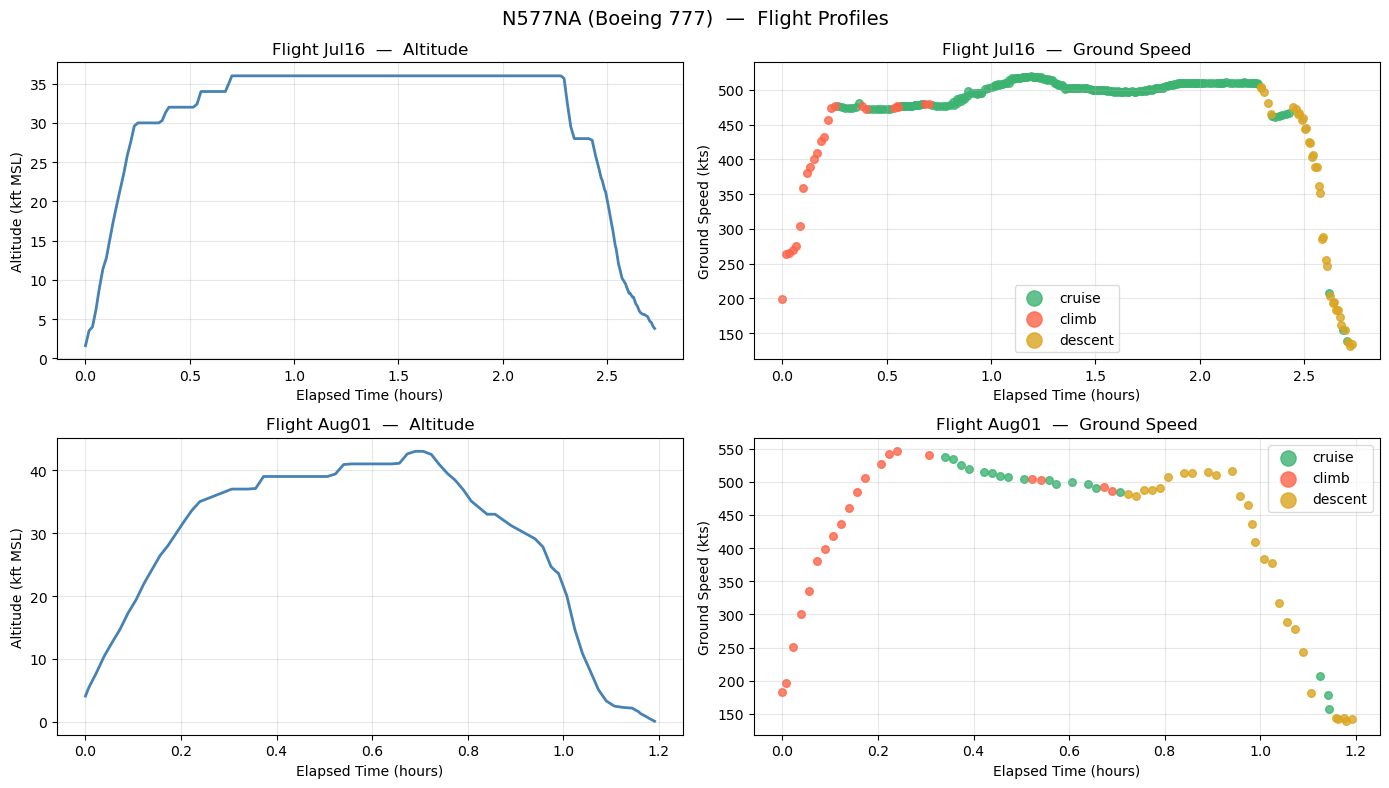

Saved N777_profile_flights.png


In [6]:
fig, axes = plt.subplots(len(dfs), 2, figsize=(14, 4 * len(dfs)))
fig.suptitle('N577NA (Boeing 777)  —  Flight Profiles', fontsize=14)

for row, (label, df) in enumerate(dfs.items()):
    ax_alt = axes[row, 0]
    ax_gs  = axes[row, 1]

    # re-classify for per-flight colouring
    ph_col = np.where(df['vspd_ms'] >  VS_CLIMB,   'climb',
              np.where(df['vspd_ms'] <  VS_DESCENT, 'descent', 'cruise'))

    ax_alt.plot(df['t_h'], df['alt_ft'] / 1000.0, color='steelblue', lw=2)
    ax_alt.set_ylabel('Altitude (kft MSL)')
    ax_alt.set_title(f'Flight {label}  —  Altitude')
    ax_alt.grid(True, alpha=0.3)

    for ph in ['cruise', 'climb', 'descent']:
        sel = ph_col == ph
        if sel.any():
            ax_gs.scatter(df['t_h'][sel], df['gspd_kts'][sel],
                          s=30, alpha=0.8, color=COLORS[ph], label=ph)
    ax_gs.set_ylabel('Ground Speed (kts)')
    ax_gs.set_title(f'Flight {label}  —  Ground Speed')
    ax_gs.legend(markerscale=2, framealpha=0.7)
    ax_gs.grid(True, alpha=0.3)

    for ax in [ax_alt, ax_gs]:
        ax.set_xlabel('Elapsed Time (hours)')

plt.tight_layout()
plt.savefig('N777_profile_flights.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved N777_profile_flights.png')

ValueError: x and y must have same first dimension, but have shapes (259,) and (65,)

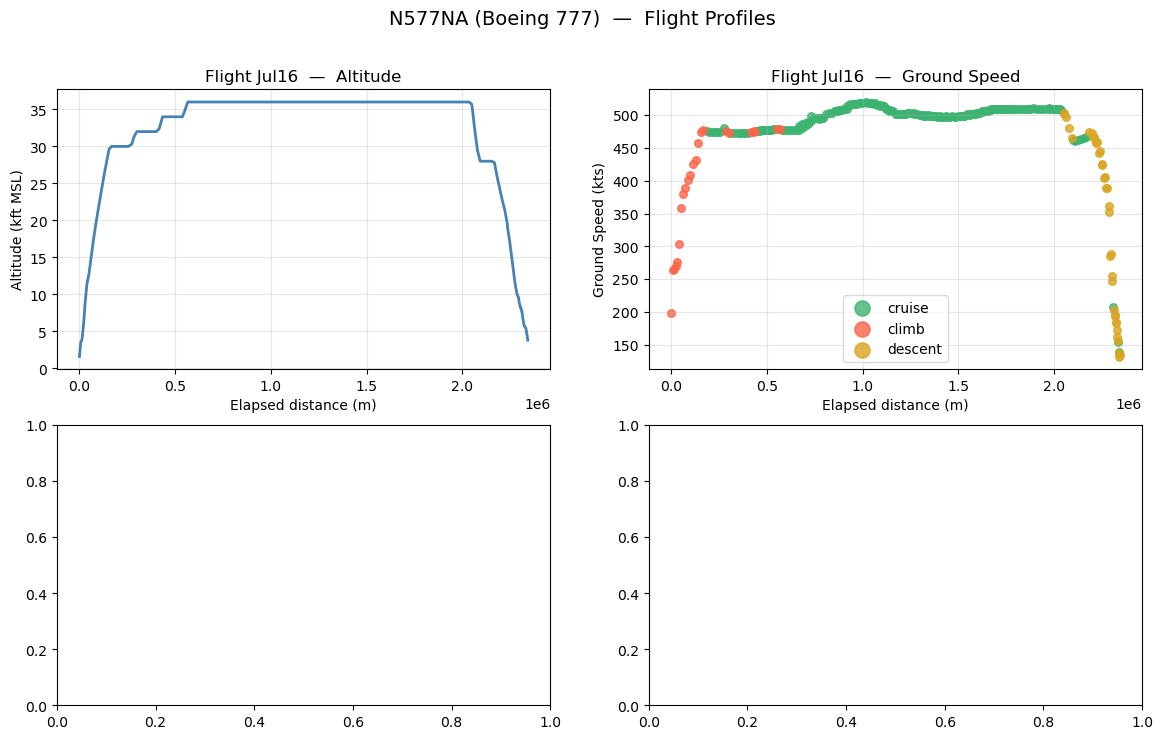

In [44]:
fig, axes = plt.subplots(len(dfs), 2, figsize=(14, 4 * len(dfs)))
fig.suptitle('N577NA (Boeing 777)  —  Flight Profiles', fontsize=14)

for row, (label, df) in enumerate(dfs.items()):
    ax_alt = axes[row, 0]
    ax_gs  = axes[row, 1]

    # re-classify for per-flight colouring
    ph_col = np.where(df['vspd_ms'] >  VS_CLIMB,   'climb',
              np.where(df['vspd_ms'] <  VS_DESCENT, 'descent', 'cruise'))

    ax_alt.plot(cumdist_m, df['alt_ft'] / 1000.0, color='steelblue', lw=2)
    ax_alt.set_ylabel('Altitude (kft MSL)')
    ax_alt.set_title(f'Flight {label}  —  Altitude')
    ax_alt.grid(True, alpha=0.3)

    for ph in ['cruise', 'climb', 'descent']:
        sel = ph_col == ph
        if sel.any():
            ax_gs.scatter(cumdist_m[sel], df['gspd_kts'][sel],
                          s=30, alpha=0.8, color=COLORS[ph], label=ph)
    ax_gs.set_ylabel('Ground Speed (kts)')
    ax_gs.set_title(f'Flight {label}  —  Ground Speed')
    ax_gs.legend(markerscale=2, framealpha=0.7)
    ax_gs.grid(True, alpha=0.3)

    for ax in [ax_alt, ax_gs]:
        ax.set_xlabel('Elapsed distance (m)')

plt.tight_layout()
plt.savefig('N777_profile_flights_distance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved N777_profile_flights_distance.png')

# Figure 2 – Ground Speed vs Altitude (All Flights)

Scatter coloured by phase, 500 m-binned medians, and a linear fit to cruise data used
to extract `base_speed` and `speed_per_alt`.

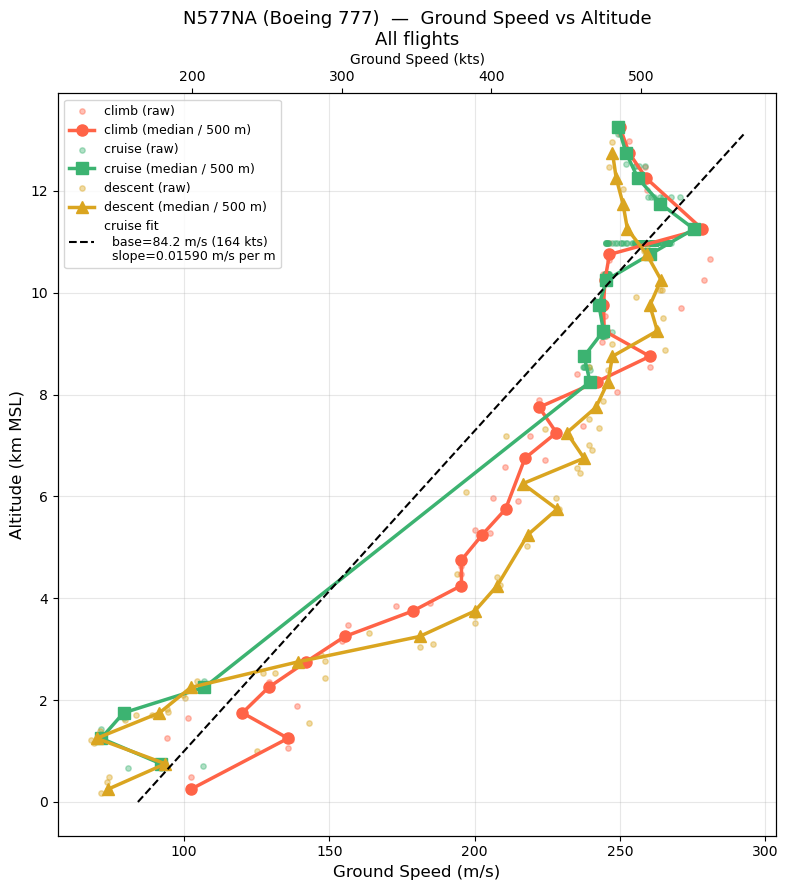

Cruise linear fit:  base_speed = 84.16 m/s (163.6 kts),  speed_per_alt = 0.015900 m/s per m,  R = 0.950


In [7]:
fig, ax = plt.subplots(figsize=(8, 9))

for ph in ['climb', 'cruise', 'descent']:
    sub = df_f[df_f['phase'] == ph]
    if len(sub) < 3:
        continue
    ax.scatter(sub['gspd_ms'], sub['alt_m'] / 1000,
               s=15, alpha=0.4, color=COLORS[ph], label=f'{ph} (raw)')
    if len(sub) >= 5:
        ac, gc = binned_med(sub['alt_m'].values, sub['gspd_ms'].values, ALT_BINS)
        ax.plot(gc, ac / 1000, color=COLORS[ph], lw=2.5,
                marker=MARKERS[ph], ms=8, label=f'{ph} (median / 500 m)')

# linear fit to cruise data
cruise = df_f[df_f['phase'] == 'cruise']
slope_gs, icept_gs, r_gs, _, _ = st.linregress(cruise['alt_m'], cruise['gspd_ms'])
alt_range = np.array([0.0, df_f['alt_m'].max()])
ax.plot(icept_gs + slope_gs * alt_range, alt_range / 1000,
        'k--', lw=1.5,
        label=(f'cruise fit\n'
               f'  base={icept_gs:.1f} m/s ({icept_gs*1.944:.0f} kts)\n'
               f'  slope={slope_gs:.5f} m/s per m'))

# secondary x-axis in knots
ax2 = ax.twiny()
ax2.set_xlim(np.array(ax.get_xlim()) * 1.94384)
ax2.set_xlabel('Ground Speed (kts)')

ax.set_xlabel('Ground Speed (m/s)', fontsize=12)
ax.set_ylabel('Altitude (km MSL)', fontsize=12)
ax.set_title('N577NA (Boeing 777)  —  Ground Speed vs Altitude\nAll flights', fontsize=13)
ax.legend(framealpha=0.8, fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('N777_gspd_vs_alt.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Cruise linear fit:  base_speed = {icept_gs:.2f} m/s ({icept_gs*1.944:.1f} kts),  '
      f'speed_per_alt = {slope_gs:.6f} m/s per m,  R = {r_gs:.3f}')

# Figure 3 – Vertical Speed vs Altitude (Climb and Descent)

Vertical speed is derived from consecutive altitude differences divided by elapsed time
(see *Extrapolate Missing Data* above).  Linear fits provide `vert_speed_base` and
`vert_speed_per_alt` for the climb phase.

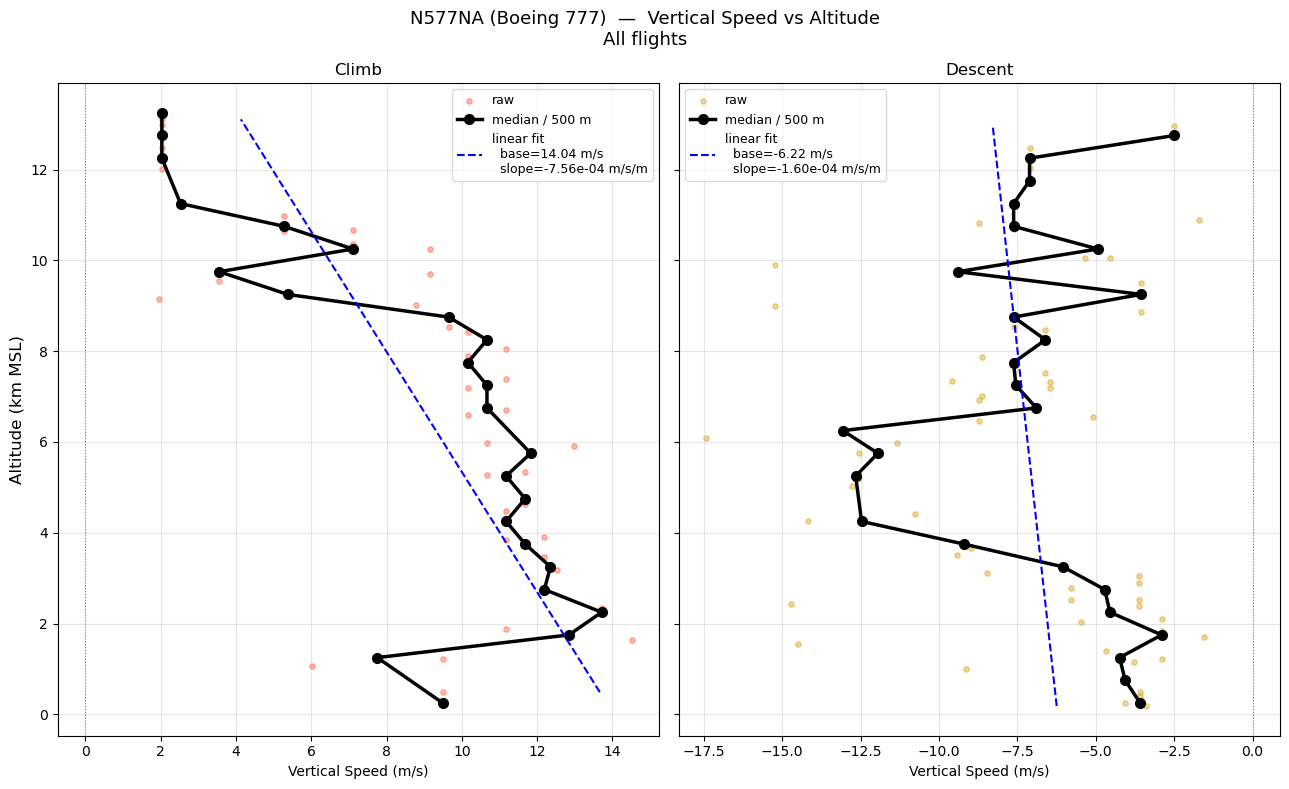

climb   : median vspd = 10.16 m/s  (2000 ft/min),  10th–90th = 2.03 – 12.45 m/s
descent : median vspd = -6.53 m/s  (-1286 ft/min),  10th–90th = -14.46 – -2.90 m/s

Climb linear fit:  vert_speed_base=14.04 m/s,  vert_speed_per_alt=-7.56e-04 m/s per m,  R=-0.739


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharey=True)
fig.suptitle('N577NA (Boeing 777)  —  Vertical Speed vs Altitude\nAll flights', fontsize=13)

linear_fit = {}
for ax, ph, col in zip(axes, ['climb', 'descent'], ['tomato', 'goldenrod']):
    sub = df_f[df_f['phase'] == ph]
    if len(sub) == 0:
        ax.set_title(f'{ph.capitalize()} — NO DATA')
        continue

    # clip extreme outliers for plotting
    lo, hi = sub['vspd_ms'].quantile([0.02, 0.98]).values
    sub_cl = sub[sub['vspd_ms'].between(lo, hi)]

    ax.scatter(sub_cl['vspd_ms'], sub_cl['alt_m'] / 1000,
               s=15, alpha=0.45, color=col, label='raw')

    if len(sub_cl) >= 5:
        ac, vc = binned_med(sub_cl['alt_m'].values, sub_cl['vspd_ms'].values, ALT_BINS)
        ax.plot(vc, ac / 1000, color='k', lw=2.5, marker='o', ms=7,
                label='median / 500 m')

    ok = sub_cl['vspd_ms'].notna() & sub_cl['alt_m'].notna()
    if ok.sum() >= 5:
        sl, ic, rv, _, _ = st.linregress(sub_cl['alt_m'][ok], sub_cl['vspd_ms'][ok])
        alt_fit = np.array([sub_cl['alt_m'].min(), sub_cl['alt_m'].max()])
        ax.plot(ic + sl * alt_fit, alt_fit / 1000,
                'b--', lw=1.5,
                label=f'linear fit\n  base={ic:.2f} m/s\n  slope={sl:.2e} m/s/m')
        linear_fit[ph] = {'base': ic, 'slope': sl, 'R': rv}

    ax.set_title(f'{ph.capitalize()}')
    ax.set_xlabel('Vertical Speed (m/s)')
    ax.legend(framealpha=0.7, fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.axvline(0, color='gray', lw=0.8, ls=':')

axes[0].set_ylabel('Altitude (km MSL)', fontsize=12)

plt.tight_layout()
plt.savefig('N777_vspd_vs_alt.png', dpi=150, bbox_inches='tight')
plt.show()

for ph in ['climb', 'descent']:
    sub = df_f[df_f['phase'] == ph]
    if len(sub) == 0:
        print(f'{ph:8s}: no data')
        continue
    lo, hi = sub['vspd_ms'].quantile([0.02, 0.98]).values
    med = sub['vspd_ms'].clip(lo, hi).median()
    p10 = sub['vspd_ms'].clip(lo, hi).quantile(0.10)
    p90 = sub['vspd_ms'].clip(lo, hi).quantile(0.90)
    print(f'{ph:8s}: median vspd = {med:.2f} m/s  '
          f'({med*196.85:.0f} ft/min),  '
          f'10th–90th = {p10:.2f} – {p90:.2f} m/s')
if 'climb' in linear_fit:
    lf = linear_fit['climb']
    print(f"\nClimb linear fit:  vert_speed_base={lf['base']:.2f} m/s,  "
          f"vert_speed_per_alt={lf['slope']:.2e} m/s per m,  R={lf['R']:.3f}")

# Figure 4 – Bank Angle Analysis

Bank angle is derived from the coordinated-turn formula using the observed heading-change
rate and ground speed (see *Extrapolate Missing Data*).  Inspection of the FL360 cruise
records shows the aircraft flies a racetrack (east–west legs, ~177° heading change per
60-second record), inflating apparent bank angles to 50–58°.  Those records are excluded
by capping at 40°.  The parameterisation value `turn_bank_angle` uses the median of
`|bank_angle|` in the range 5°–40° with ground speed > 100 m/s.

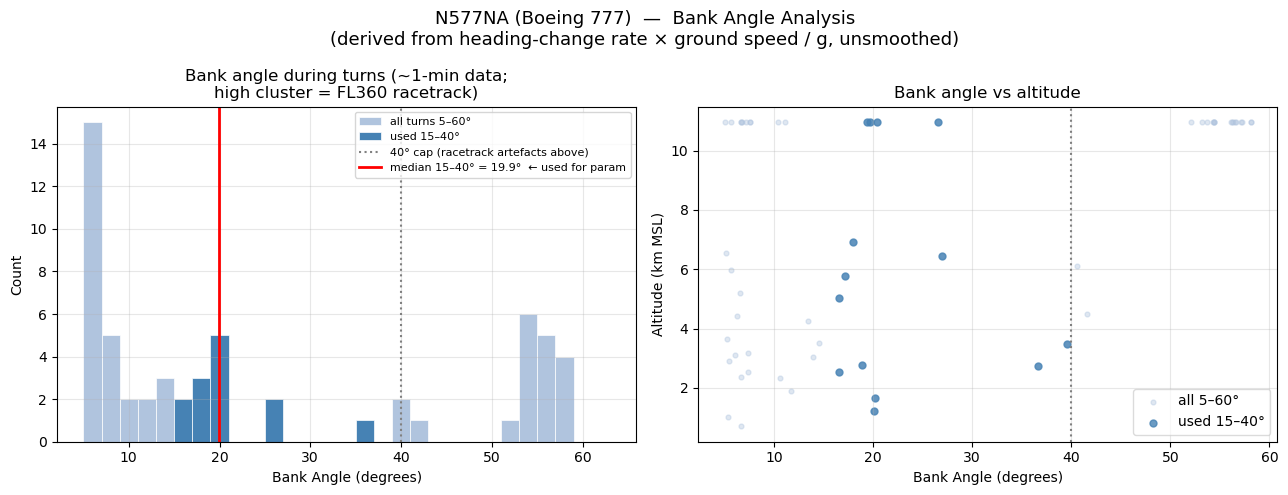

All turns 5–60°:   n=59,  median=17.2°
Filtered 15–40°:   n=14,  median=19.9°,  75th=25.0°  (used for turn_bank_angle)


In [9]:
# Use unsmoothed bank_angle_raw (per-interval) so peak turn values are not
# suppressed by the rolling median used for phase classification.

# Full view 5–60° to show the racetrack artefact
turn_wide = (
    df_f['gspd_ms'].gt(100) &
    df_f['bank_angle_raw'].gt(5) &
    df_f['bank_angle_raw'].lt(60) &
    df_f['bank_angle_raw'].notna()
)
ba_wide  = df_f.loc[turn_wide, 'bank_angle_raw'].values
alt_wide = df_f.loc[turn_wide, 'alt_m'].values

# Parameterisation-quality subset: 15–40°, excludes noise AND racetrack artefacts
turn_param = (
    df_f['gspd_ms'].gt(100) &
    df_f['bank_angle_raw'].gt(15) &
    df_f['bank_angle_raw'].lt(40) &
    df_f['bank_angle_raw'].notna()
)
ba_param_plot  = df_f.loc[turn_param, 'bank_angle_raw'].values
alt_param_plot = df_f.loc[turn_param, 'alt_m'].values

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('N577NA (Boeing 777)  —  Bank Angle Analysis\n'
             '(derived from heading-change rate × ground speed / g, unsmoothed)', fontsize=13)

# histogram — full view with cap marker
axes[0].hist(ba_wide, bins=np.arange(5, 65, 2), color='lightsteelblue',
             edgecolor='white', lw=0.5, label='all turns 5–60°')
axes[0].hist(ba_param_plot, bins=np.arange(15, 41, 2), color='steelblue',
             edgecolor='white', lw=0.5, label='used 15–40°')
axes[0].axvline(40, color='gray', lw=1.5, ls=':',
                label='40° cap (racetrack artefacts above)')
if len(ba_param_plot):
    axes[0].axvline(np.median(ba_param_plot), color='red', lw=2,
                    label=f'median 15–40° = {np.median(ba_param_plot):.1f}°  ← used for param')
axes[0].set_xlabel('Bank Angle (degrees)')
axes[0].set_ylabel('Count')
axes[0].set_title('Bank angle during turns (~1-min data;\nhigh cluster = FL360 racetrack)')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

# bank angle vs altitude
axes[1].scatter(ba_wide, alt_wide / 1000, s=12, alpha=0.4,
                color='lightsteelblue', label='all 5–60°')
axes[1].scatter(ba_param_plot, alt_param_plot / 1000, s=25, alpha=0.8,
                color='steelblue', label='used 15–40°')
axes[1].axvline(40, color='gray', lw=1.5, ls=':')
axes[1].set_xlabel('Bank Angle (degrees)')
axes[1].set_ylabel('Altitude (km MSL)')
axes[1].set_title('Bank angle vs altitude')
axes[1].legend(framealpha=0.7)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('N777_bank_angle.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'All turns 5–60°:   n={len(ba_wide)},  median={np.median(ba_wide):.1f}°')
if len(ba_param_plot):
    print(f'Filtered 15–40°:   n={len(ba_param_plot)},  '
          f'median={np.median(ba_param_plot):.1f}°,  '
          f'75th={np.percentile(ba_param_plot, 75):.1f}°  (used for turn_bank_angle)')

# Figure 5 – Cruise Altitude Histogram

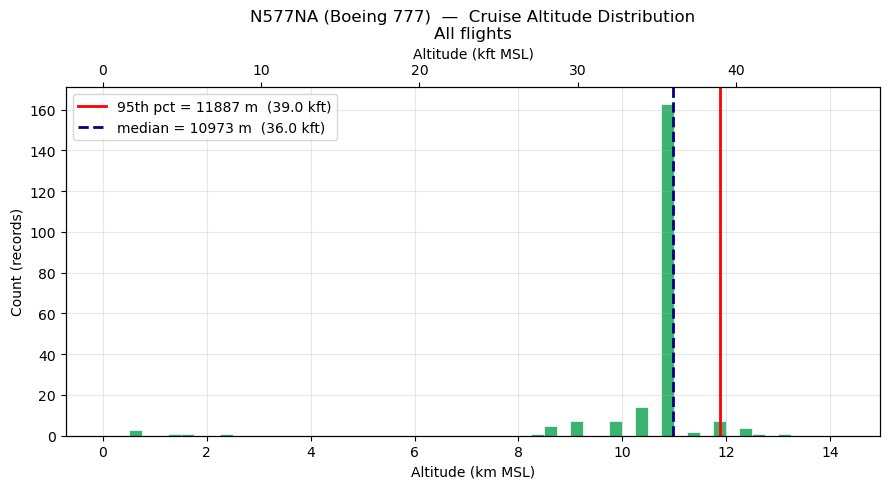

Cruise alt: median=10973 m (36.0 kft),  95th pct=11887 m (39.0 kft),  max=13106 m (43.0 kft)


In [10]:
cruise = df_f[df_f['phase'] == 'cruise']
alt_cruise = cruise['alt_m'].values

fig, ax = plt.subplots(figsize=(9, 5))

bins_km = np.arange(0, 14.5, 0.25)
ax.hist(alt_cruise / 1000, bins=bins_km, color='mediumseagreen',
        edgecolor='white', lw=0.5)

p95 = np.percentile(alt_cruise, 95)
med = np.median(alt_cruise)
ax.axvline(p95 / 1000, color='red', lw=2, label=f'95th pct = {p95:.0f} m  ({p95*3.281/1000:.1f} kft)')
ax.axvline(med / 1000, color='navy', lw=2, ls='--', label=f'median = {med:.0f} m  ({med*3.281/1000:.1f} kft)')

# secondary x-axis in feet
ax2 = ax.twiny()
ax2.set_xlim(np.array(ax.get_xlim()) * 3.281)
ax2.set_xlabel('Altitude (kft MSL)')

ax.set_xlabel('Altitude (km MSL)')
ax.set_ylabel('Count (records)')
ax.set_title('N577NA (Boeing 777)  —  Cruise Altitude Distribution\nAll flights')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('N777_cruise_alt_hist.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Cruise alt: median={med:.0f} m ({med*3.281/1000:.1f} kft),  '
      f'95th pct={p95:.0f} m ({p95*3.281/1000:.1f} kft),  '
      f'max={alt_cruise.max():.0f} m ({alt_cruise.max()*3.281/1000:.1f} kft)')

# Figure 6 – Speed Distribution by Phase and Altitude Bin

Box-and-whisker plot of ground speed vs altitude for all three phases, showing
the spread of observations used in the linear fit.

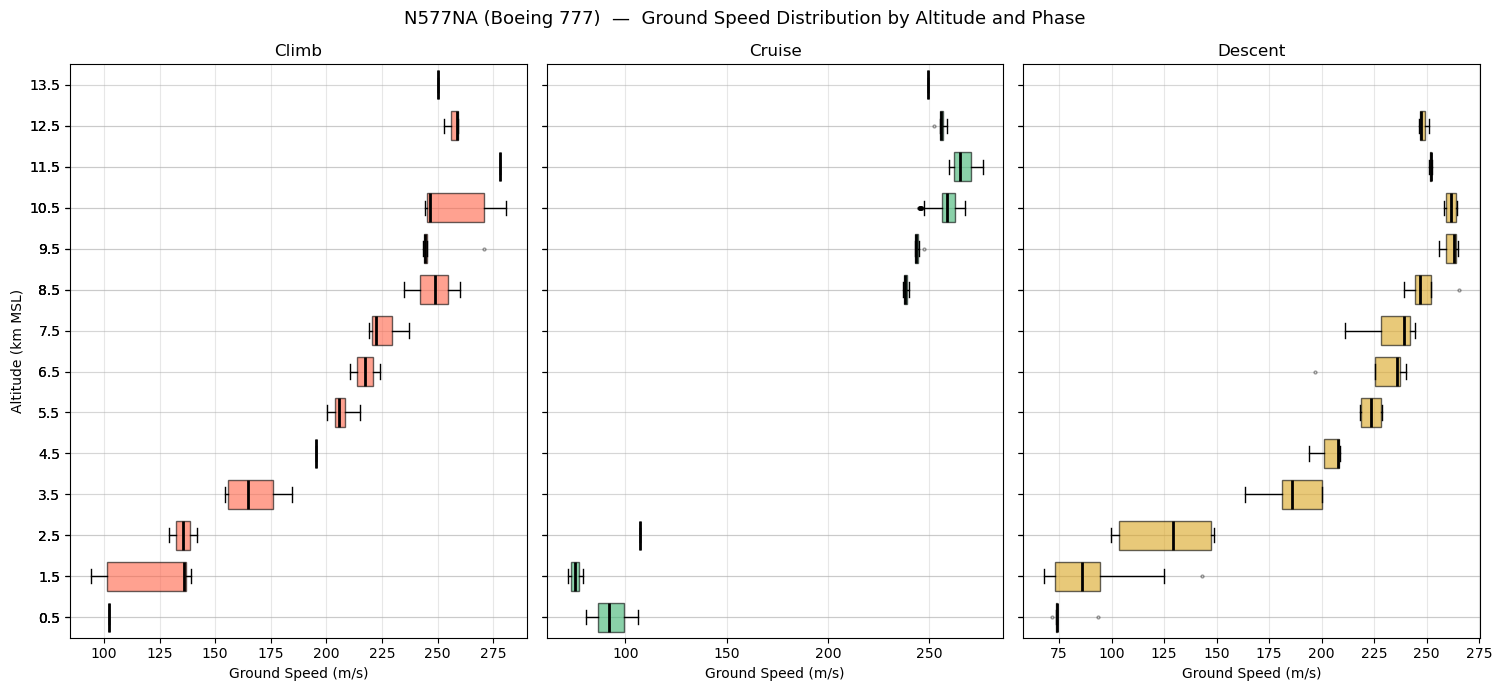

Saved N777_gspd_dist_by_alt.png


In [11]:
BIN_EDGES  = np.arange(0, 14501, 1000)   # 1 km bins
BIN_LABELS = [f'{e/1000:.0f}–{(e+1000)/1000:.0f}' for e in BIN_EDGES[:-1]]

fig, axes = plt.subplots(1, 3, figsize=(15, 7), sharey=True)
fig.suptitle('N577NA (Boeing 777)  —  Ground Speed Distribution by Altitude and Phase',
             fontsize=13)

for ax, ph in zip(axes, ['climb', 'cruise', 'descent']):
    sub = df_f[df_f['phase'] == ph]
    if len(sub) == 0:
        ax.set_title(f'{ph.capitalize()} — NO DATA')
        continue
    sub = sub.copy()
    sub['alt_bin'] = pd.cut(sub['alt_m'], bins=BIN_EDGES, labels=BIN_LABELS[:len(BIN_EDGES)-1])
    grouped = [sub.loc[sub['alt_bin'] == lbl, 'gspd_ms'].dropna().values
               for lbl in BIN_LABELS[:len(BIN_EDGES)-1]]
    nonempty = [(i, g) for i, g in enumerate(grouped) if len(g) > 0]
    if nonempty:
        pos   = [BIN_EDGES[i] / 1000 + 0.5 for i, _ in nonempty]
        data  = [g for _, g in nonempty]
        bp = ax.boxplot(data, positions=pos, widths=0.7,
                        vert=False, patch_artist=True,
                        boxprops=dict(facecolor=COLORS[ph], alpha=0.6),
                        medianprops=dict(color='black', lw=2),
                        flierprops=dict(marker='.', ms=4, alpha=0.4))
    ax.set_title(ph.capitalize())
    ax.set_xlabel('Ground Speed (m/s)')
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Altitude (km MSL)')
axes[0].set_ylim(0, 14)

plt.tight_layout()
plt.savefig('N777_gspd_dist_by_alt.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved N777_gspd_dist_by_alt.png')

# Derive Platform Parameters

All quantities in SI units (metres, m/s) to match the platform configuration format.

In [12]:
cruise_m  = df_f['phase'] == 'cruise'
climb_m   = df_f['phase'] == 'climb'
descent_m = df_f['phase'] == 'descent'

alt_f_v   = df_f['alt_m'].values
gspd_f_v  = df_f['gspd_ms'].values
vspd_f_v  = df_f['vspd_ms'].values

# ---- max_alt: 99th percentile of in-flight altitude ----
max_alt = np.percentile(alt_f_v, 99)

# ---- ground speed parameterisation: linear cruise fit ----
slope_gs, icept_gs, _, _, _ = st.linregress(alt_f_v[cruise_m], gspd_f_v[cruise_m])
base_speed    = icept_gs
speed_per_alt = slope_gs

# ---- max_speed and max_speed_alt ----
max_speed = np.percentile(gspd_f_v, 99)
near_max  = gspd_f_v >= max_speed * 0.98
max_speed_alt = np.median(alt_f_v[near_max]) if near_max.sum() > 0 else np.nan

# ---- descent_speed_decrease: median positive (cruise > descent) GS diff vs altitude ----
# Only use bins where cruise is measurably faster than descent; the descent data spans
# the full approach (slow at low altitude) so many bins show negative diffs.
if descent_m.sum() >= 3:
    shared_bins = np.arange(1000, 14001, 1000)
    gs_cr, _, _ = binned_statistic(alt_f_v[cruise_m],  gspd_f_v[cruise_m],  'median', bins=shared_bins)
    gs_de, _, _ = binned_statistic(alt_f_v[descent_m], gspd_f_v[descent_m], 'median', bins=shared_bins)
    diff = gs_cr - gs_de
    pos_diff = diff[np.isfinite(diff) & (diff > 0)]
    if len(pos_diff) >= 2:
        descent_speed_decrease = float(np.median(pos_diff))
    else:
        high = alt_f_v >= 9000
        descent_speed_decrease = float(
            np.nanmedian(gspd_f_v[cruise_m & high]) - np.nanmedian(gspd_f_v[descent_m & high]))
        print('NOTE: descent_speed_decrease estimated from high-altitude (≥9 km) medians')
else:
    descent_speed_decrease = 10.0
    print('WARNING: no descent data — using 10.0 m/s default for descent_speed_decrease')

# ---- vertical speed parameterisation (climb) ----
climb_vert_speed   = float(np.nanmedian(vspd_f_v[climb_m]))   if climb_m.sum()   > 0 else np.nan
descent_vert_speed = float(np.nanmedian(vspd_f_v[descent_m])) if descent_m.sum() > 0 else np.nan

# linear fit: vspd vs altitude for climb
if climb_m.sum() >= 5:
    vs_vals = vspd_f_v[climb_m]
    vs_cl   = pd.Series(vs_vals).clip(*pd.Series(vs_vals).quantile([0.02, 0.98]).values)
    slope_vc, icept_vc, _, _, _ = st.linregress(alt_f_v[climb_m], vs_cl)
    vert_speed_base    = float(icept_vc)
    vert_speed_per_alt = float(slope_vc)
else:
    vert_speed_base    = climb_vert_speed if not np.isnan(climb_vert_speed) else 8.0
    vert_speed_per_alt = 0.0

# alt_for_variable_vert_speed: altitude where climb rate first deviates > 1 m/s from median
if climb_m.sum() >= 5:
    vspd_bins = np.arange(0, 14001, 1000)
    vs_bin, edges, _ = binned_statistic(alt_f_v[climb_m], vspd_f_v[climb_m], 'median', bins=vspd_bins)
    centres = 0.5 * (edges[:-1] + edges[1:])
    ok_c    = np.isfinite(vs_bin)
    dev     = np.abs(vs_bin[ok_c] - climb_vert_speed) > 1.0
    dev_alt = centres[ok_c][dev]
    if len(dev_alt) > 0 and dev_alt.min() < 2000:
        alt_for_variable_vert_speed = 0.0
    elif len(dev_alt) > 0:
        alt_for_variable_vert_speed = float(dev_alt.min())
    else:
        alt_for_variable_vert_speed = float(np.nanpercentile(alt_f_v[climb_m], 50))
else:
    alt_for_variable_vert_speed = 0.0

# ---- turn bank angle: median |bank_angle_raw| for 15–40° at speed > 100 m/s ----
# Use unsmoothed per-interval bank_angle_raw so turn peaks are not suppressed.
# 15° lower bound: exclude GPS heading noise.  40° upper bound: exclude FL360 racetrack.
turn_mask_param = (
    df_f['gspd_ms'].gt(100) &
    df_f['bank_angle_raw'].gt(15) &
    df_f['bank_angle_raw'].lt(40) &
    df_f['bank_angle_raw'].notna()
)
ba_param_v = df_f.loc[turn_mask_param, 'bank_angle_raw'].values
if len(ba_param_v) >= 3:
    turn_bank_angle = float(np.median(ba_param_v))
else:
    turn_bank_angle = 25.0
    print('NOTE: insufficient committed-turn data — using 25° default for turn_bank_angle')

print('=== Derived N577NA (Boeing 777) Platform Parameters ===')
print(f'  max_alt                     = {max_alt:.0f}  m  ({max_alt*3.281/1000:.1f} kft)')
print(f'  base_speed                  = {base_speed:.1f}  m/s  ({base_speed*1.944:.0f} kts)')
print(f'  speed_per_alt               = {speed_per_alt:.5f}  m/s per m')
print(f'  max_speed                   = {max_speed:.1f}  m/s  ({max_speed*1.944:.0f} kts)')
print(f'  max_speed_alt               = {max_speed_alt:.0f}  m  ({max_speed_alt*3.281/1000:.1f} kft)')
print(f'  descent_speed_decrease      = {descent_speed_decrease:.1f}  m/s')
print(f'  climb_vert_speed            = {climb_vert_speed:.1f}  m/s  ({climb_vert_speed*196.85:.0f} ft/min)')
print(f'  descent_vert_speed          = {descent_vert_speed:.1f}  m/s  ({descent_vert_speed*196.85:.0f} ft/min)')
print(f'  alt_for_variable_vert_speed = {alt_for_variable_vert_speed:.0f}  m')
print(f'  vert_speed_base             = {vert_speed_base:.2f}  m/s')
print(f'  vert_speed_per_alt          = {vert_speed_per_alt:.2e}  m/s per m')
print(f'  turn_bank_angle             = {turn_bank_angle:.1f}  degrees  '
      f'(n={len(ba_param_v)}, bank_angle_raw 15–40°)')

=== Derived N577NA (Boeing 777) Platform Parameters ===
  max_alt                     = 12860  m  (42.2 kft)
  base_speed                  = 84.2  m/s  (164 kts)
  speed_per_alt               = 0.01590  m/s per m
  max_speed                   = 275.9  m/s  (536 kts)
  max_speed_alt               = 11278  m  (37.0 kft)
  descent_speed_decrease      = 10.7  m/s
  climb_vert_speed            = 10.2  m/s  (2000 ft/min)
  descent_vert_speed          = -6.5  m/s  (-1286 ft/min)
  alt_for_variable_vert_speed = 0  m
  vert_speed_base             = 14.25  m/s
  vert_speed_per_alt          = -7.96e-04  m/s per m
  turn_bank_angle             = 19.9  degrees  (n=14, bank_angle_raw 15–40°)


# Suggested Platform File Entry

In [13]:
entry = (
    "{'Platform':'n577na',"
    "'names':['n577na','N577NA','b777','B777','777','Boeing 777','boeing_777','B-777'],\n"
    f"    'max_alt':{max_alt:.0f}.0,"
    f"'base_speed':{base_speed:.1f},"
    f"'speed_per_alt':{speed_per_alt:.4f},\n"
    f"    'max_speed':{max_speed:.1f},"
    f"'max_speed_alt':{max_speed_alt:.0f}.0,"
    f"'descent_speed_decrease':{descent_speed_decrease:.1f},\n"
    f"    'climb_vert_speed':{climb_vert_speed:.1f},"
    f"'descent_vert_speed':{descent_vert_speed:.1f},"
    f"'alt_for_variable_vert_speed':{alt_for_variable_vert_speed:.0f}.0,\n"
    f"    'vert_speed_base':{vert_speed_base:.2f},"
    f"'vert_speed_per_alt':{vert_speed_per_alt:.2e},\n"
    "    'rate_of_turn':None,"
    f"'turn_bank_angle':{turn_bank_angle:.1f},\n"
    "    'warning':False,"
    "'pilot_format':'DD MM',\n"
    "    'preferred_file_format':['foreflight','rdme']}"
)
print(entry)

{'Platform':'n577na','names':['n577na','N577NA','b777','B777','777','Boeing 777','boeing_777','B-777'],
    'max_alt':12860.0,'base_speed':84.2,'speed_per_alt':0.0159,
    'max_speed':275.9,'max_speed_alt':11278.0,'descent_speed_decrease':10.7,
    'climb_vert_speed':10.2,'descent_vert_speed':-6.5,'alt_for_variable_vert_speed':0.0,
    'vert_speed_base':14.25,'vert_speed_per_alt':-7.96e-04,
    'rate_of_turn':None,'turn_bank_angle':19.9,
    'warning':False,'pilot_format':'DD MM',
    'preferred_file_format':['foreflight','rdme']}
